In [23]:
%pip install ucimlrepo
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
dataset = fetch_ucirepo(id=565) 
  
# data (as pandas dataframes) 
X = dataset.data.features 
Y = dataset.data.targets

   survival_status
0                0
1                1
2                1
3                1
4                0


## 1. Exploratory Data Analysis

In [2]:
import pandas as pd
import numpy as np

# Missing values analysis
missing_values_in_columns = X.isnull().sum()
features_with_missing_values = missing_values_in_columns[missing_values_in_columns > 0]

missing_df = pd.DataFrame({
    'Number of missing values': features_with_missing_values,
    'Percentage of missing values (%)': (features_with_missing_values / len(X) * 100).round(2)
}).sort_values(by='Number of missing values', ascending=False)

print("=== 1. Features with missing values ===")
print(missing_df)
print("\n")


=== 1. Features with missing values ===
              Number of missing values  Percentage of missing values (%)
extcGvHD                            31                             16.58
CMVstatus                           16                              8.56
RecipientCMV                        14                              7.49
CD3dCD34                             5                              2.67
CD3dkgx10d8                          5                              2.67
DonorCMV                             2                              1.07
RecipientRh                          2                              1.07
Rbodymass                            2                              1.07
ABOmatch                             1                              0.53
RecipientABO                         1                              0.53
Allele                               1                              0.53
Antigen                              1                              0.53




In [3]:
X_cleaned = X.copy()

for col in features_with_missing_values.index:
    if np.issubdtype(X_cleaned[col].dtype, np.number):
        X_cleaned[col] = X_cleaned[col].fillna(X_cleaned[col].median())
    else:
        X_cleaned[col] = X_cleaned[col].fillna(X_cleaned[col].mode()[0])

print("Missing values after filling missing values:", X_cleaned.isnull().sum().sum())

Missing values after filling missing values: 0


In [8]:
from lifelines import CoxPHFitter
import pandas as pd

df_survival = X.copy()
df_survival['event'] = Y

TIME_COL = 'survival_time'
EVENT_COL = 'event'

results = []
numeric_cols = X.select_dtypes(include=['number']).columns
numeric_cols = [c for c in numeric_cols if c != TIME_COL]

for col in numeric_cols:
    temp_df = df_survival[[col, TIME_COL, EVENT_COL]].dropna()
    
    if len(temp_df) < 10:
        continue
        
    try:
        cph = CoxPHFitter()
        cph.fit(temp_df, duration_col=TIME_COL, event_col=EVENT_COL)
        
        c_index = cph.concordance_index_
        p_value = cph.summary.loc[col, 'p']
        
        results.append({
            'Feature': col,
            'C_Index': c_index,
            'P_Value': p_value
        })
    except Exception:
        continue

survival_df = pd.DataFrame(results)

survival_df['C_Index_Deviation'] = (survival_df['C_Index'] - 0.5).abs()
survival_df = survival_df.sort_values(by='C_Index_Deviation', ascending=False)

print("=== Model Coxa / C-Index z uwzględnieniem cenzurowania (Top 5) ===")
print(survival_df.head(5).to_string(index=False))

uncorrelated_features_001 = survival_df[survival_df['C_Index_Deviation'] < 0.01]
uncorrelated_features_005 = survival_df[survival_df['C_Index_Deviation'] < 0.05]
uncorrelated_features_003 = survival_df[survival_df['C_Index_Deviation'] < 0.03]

print("\nNumber of features not strongly associated with survival (|C_Index - 0.5| < 0.05):", len(uncorrelated_features_005))
print("Number of features not strongly associated with survival (|C_Index - 0.5| < 0.03):", len(uncorrelated_features_003))
print("Number of features not strongly associated with survival (|C_Index - 0.5| < 0.01):", len(uncorrelated_features_001))

print("\n=== Features not strongly associated with survival (|C_Index - 0.5| < 0.01) ===")
print(uncorrelated_features_001.to_string(index=False))

=== Model Coxa / C-Index z uwzględnieniem cenzurowania (Top 5) ===
     Feature  C_Index      P_Value  C_Index_Deviation
 PLTrecovery 0.617566 3.495186e-17           0.117566
 CD3dkgx10d8 0.606665 2.440876e-03           0.106665
Recipientage 0.597924 2.820241e-03           0.097924
 CD34kgx10d6 0.595806 3.477799e-02           0.095806
   Rbodymass 0.594687 3.019255e-04           0.094687

Number of features not strongly associated with survival (|C_Index - 0.5| < 0.05): 22
Number of features not strongly associated with survival (|C_Index - 0.5| < 0.03): 16
Number of features not strongly associated with survival (|C_Index - 0.5| < 0.01): 7

=== Features not strongly associated with survival (|C_Index - 0.5| < 0.01) ===
        Feature  C_Index  P_Value  C_Index_Deviation
        Antigen 0.509493 0.744894           0.009493
   RecipientCMV 0.508830 0.741560           0.008830
Recipientgender 0.505814 0.772106           0.005814
   RecipientABO 0.495065 0.997290           0.004935
     

c:\Users\keraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1679: RuntimeWarning: overflow encountered in exp
  scores = weights * exp(dot(X, beta))
c:\Users\keraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1731: RuntimeWarning: divide by zero encountered in divide
  denom = 1.0 / np.array([risk_phi])
c:\Users\keraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1733: RuntimeWarning: invalid value encountered in multiply
  a1 = risk_phi_x_x * denom
c:\Users\keraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1735: RuntimeWarning: invalid value encountered in multiply
  summand = numer * denom[:, None]
c:\Users\keraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1727: RuntimeWarning: divide by zero encountered in divide
  denom = 1.0 / (risk_phi - increasing

In [28]:
corr_matrix = X_cleaned.corr(method='spearman', numeric_only=True).abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = [
    (col1, col2, upper_tri.loc[col1, col2]) 
    for col1 in upper_tri.columns 
    for col2 in upper_tri.index 
    if upper_tri.loc[col1, col2] > 0.75
]

jointly_correlated_df = pd.DataFrame(high_corr_pairs, columns=['Feature_1', 'Feature_2', 'Correlation']).sort_values(by='Correlation', ascending=False)

print("=== Features with High Correlation (|r| > 0.75) ===")
print(jointly_correlated_df.to_string(index=False))

=== Features with High Correlation (|r| > 0.75) ===
      Feature_1            Feature_2  Correlation
       HLAmatch               HLAgrI     0.981849
     aGvHDIIIIV time_to_aGvHD_III_IV     0.972161
         Allele               HLAgrI     0.961067
       HLAmatch               Allele     0.948641
       HLAmatch              Antigen     0.932895
   Recipientage      Recipientageint     0.925281
 Recipientage10      Recipientageint     0.924962
   Recipientage            Rbodymass     0.924537
        Antigen               HLAgrI     0.885886
Recipientageint            Rbodymass     0.879909
   Recipientage       Recipientage10     0.864583
      CMVstatus         RecipientCMV     0.863746
       Donorage           Donorage35     0.860560
        Antigen               Allele     0.834164
 Recipientage10            Rbodymass     0.815575


In [29]:
redundant_features = [
    'HLAgrI', 'Allele', 'Antigen',
    'Recipientageint', 'Recipientage10', 'Rbodymass',
    'time_to_aGvHD_III_IV',
    'Donorage35',
    'RecipientCMV'
]

X_final = X_cleaned.drop(columns=redundant_features)

if 'survival_time' in X_final.columns:
    X_final = X_final.drop(columns=['survival_time'])

print(f"Number of features before cleaning: {X.shape[1]}")
print(f"Final number of features for clustering: {X_final.shape[1]}")

Number of features before cleaning: 36
Final number of features for clustering: 26


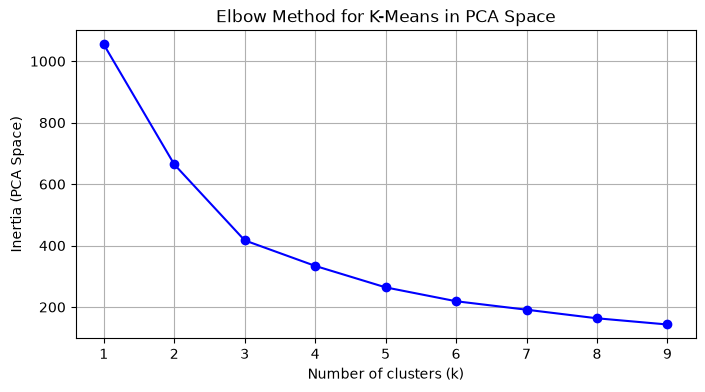

=== Number of samples in each cluster ===
cluster_pca
2    98
0    54
1    35
Name: count, dtype: int64


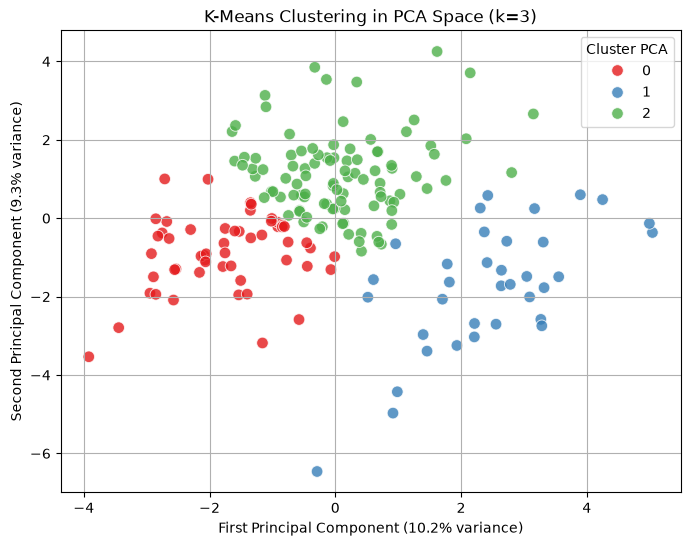

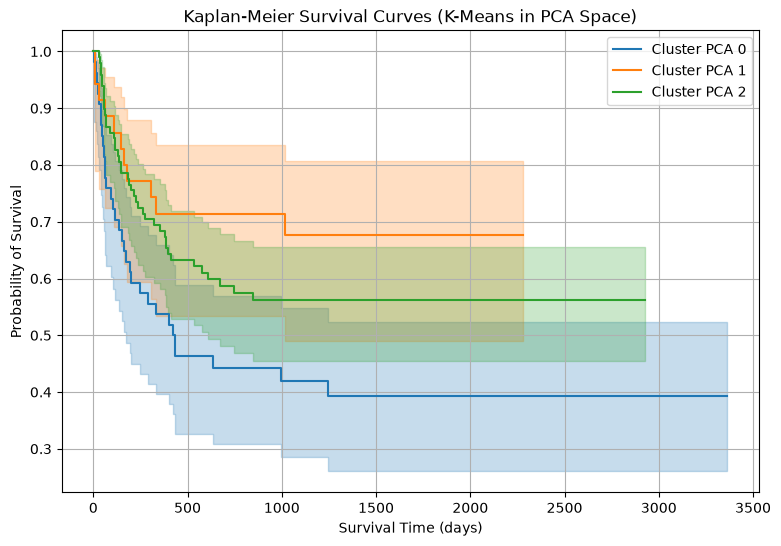

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_final_numeric = pd.get_dummies(X_final, drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final_numeric)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

inertia_pca = []
K_range = range(1, 10)

for k in K_range:
  kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans_pca.fit(X_pca)
  inertia_pca.append(kmeans_pca.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia_pca, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (PCA Space)')
plt.title('Elbow Method for K-Means in PCA Space')
plt.grid(True)
plt.show()

k_optimal = 3
kmeans_pca = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters_pca = kmeans_pca.fit_predict(X_pca)

X_final_clustered_pca = X_final.copy()
X_final_clustered_pca['cluster_pca'] = clusters_pca

print("=== Number of samples in each cluster ===")
print(X_final_clustered_pca['cluster_pca'].value_counts())

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_pca,
    palette='Set1',
    s=70,
    alpha=0.8,
)
plt.title(f'K-Means Clustering in PCA Space (k={k_optimal})')
plt.xlabel(
    f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}% variance)'
)
plt.ylabel(
    f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}% variance)'
)
plt.legend(title='Cluster PCA')
plt.grid(True)
plt.show()

df_survival_pca = X_final_clustered_pca.copy()
df_survival_pca['survival_time'] = X['survival_time']
df_survival_pca['survival_status'] = Y['survival_status']

kmf = KaplanMeierFitter()
plt.figure(figsize=(9, 6))

for cluster_id in sorted(df_survival_pca['cluster_pca'].unique()):
  mask = df_survival_pca['cluster_pca'] == cluster_id
  kmf.fit(
      durations=df_survival_pca.loc[mask, 'survival_time'],
      event_observed=df_survival_pca.loc[mask, 'survival_status'],
      label=f'Cluster PCA {cluster_id}',
  )
  kmf.plot_survival_function(ci_show=True)

plt.title('Kaplan-Meier Survival Curves (K-Means in PCA Space)')
plt.xlabel('Survival Time (days)')
plt.ylabel('Probability of Survival')
plt.grid(True)
plt.show()

if k_optimal == 2:
  c0 = df_survival_pca[df_survival_pca['cluster_pca'] == 0]
  c1 = df_survival_pca[df_survival_pca['cluster_pca'] == 1]

  res_logrank = logrank_test(
      c0['survival_time'],
      c1['survival_time'],
      event_observed_A=c0['survival_status'],
      event_observed_B=c1['survival_status'],
  )

  print("=== Log-Rank Test for PCA Clusters ===")
  print(f"p-value: {res_logrank.p_value:.5f}")


<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -373.43
         time fit was run = 2026-11-12 14:15:07 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
Recipientgender      -0.04      0.96      0.23           -0.49            0.40                0.61                1.50
Stemcellsource       -0.04      0.96      0.28           -0.59            0.51                0.56                1.67
Donorage              0.02      1.02      0.01           -0.01            0.05                0.99                1.05
IIIV                  0.11      1.11      0.24           -0.36            0.57                0.70                1.78
Gendermatch           0.11      1.12      0.30           -0.47            0.69                0.63                2.00
DonorABO              0.11      1.11      0.13           -0.14            0.35                0.87                1.43
RecipientABO         -0.06      0.94      0.12           -0.29            0.17                0.75                1.18
RecipientRh           0.77      2.15      0.32            0.14            1.40                1.15                4.05
ABOmatch             -0.09      0.92      0.23           -0.54            0.37                0.58                1.44
CMVstatus            -0.02      0.98      0.10           -0.22            0.19                0.80                1.20
DonorCMV             -0.12      0.89      0.23           -0.57            0.34                0.56                1.41
Riskgroup             0.08      1.08      0.26           -0.42            0.58                0.66                1.79
Txpostrelapse        -0.02      0.98      0.32           -0.65            0.61                0.52                1.85
Diseasegroup         -0.11      0.90      0.47           -1.02            0.80                0.36                2.23
HLAmatch              0.12      1.13      0.17           -0.22            0.47                0.80                1.60
HLAmismatch          -0.21      0.81      0.38           -0.95            0.53                0.39                1.71
Recipientage          0.03      1.03      0.02           -0.01            0.08                0.99                1.08
Relapse               0.92      2.52      0.27            0.39            1.46                1.48                4.31
aGvHDIIIIV           -0.59      0.55      0.27           -1.12           -0.06                0.33                0.95
extcGvHD             -0.38      0.68      0.28           -0.93            0.17                0.39                1.19
CD34kgx10d6           0.00      1.00      0.01           -0.02            0.03                0.98                1.03
CD3dCD34              0.00      1.00      0.01           -0.02            0.02                0.98                1.02
CD3dkgx10d8          -0.05      0.95      0.04           -0.12            0.02                0.89                1.02
ANCrecovery           0.00      1.00      0.00            0.00            0.00                1.00                1.00
PLTrecovery           0.00      1.00      0.00            0.00            0.00                1.00                1.00
Disease_AML           0.05      1.05      0.31           -0.56            0.65                0.57                1.91
Disease_chronic      -0.08      0.93      0.28           -0.63            0.47                0.53                1.60
Disease_lymphoma      0.60      1.82      0.44           -0.26            1.46                0.77            

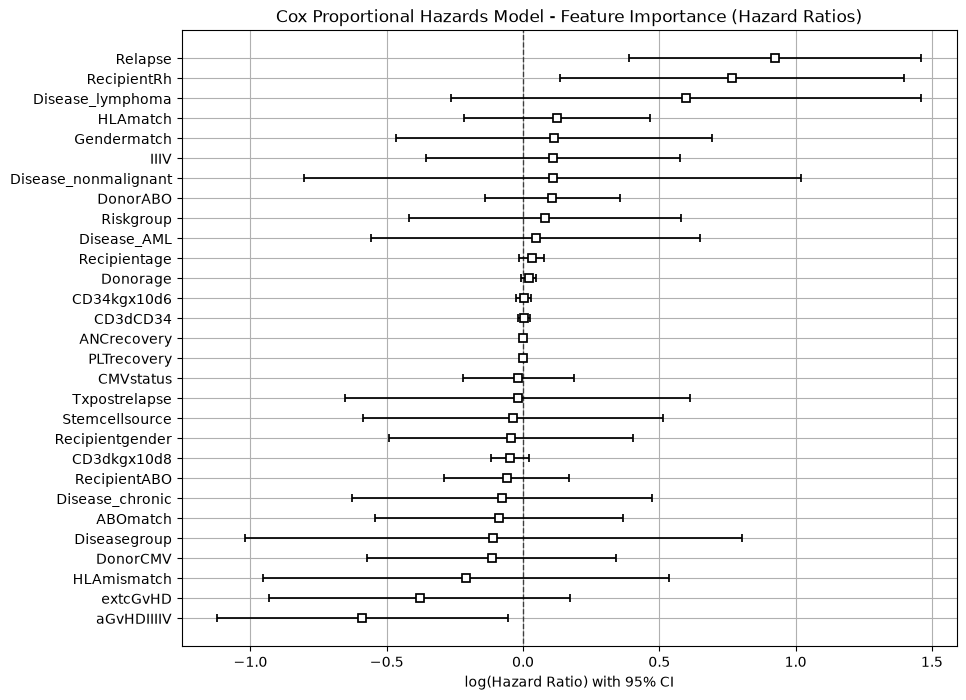

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter

df_cox = X_final_numeric.copy()
df_cox['survival_time'] = X['survival_time']
df_cox['survival_status'] = Y['survival_status']

cph = CoxPHFitter(penalizer=0.1)
cph.fit(
    df_cox,
    duration_col='survival_time',
    event_col='survival_status',
    show_progress=False,
)

cph.print_summary()

plt.figure(figsize=(10, 8))
cph.plot()
plt.title('Cox Proportional Hazards Model - Feature Importance (Hazard Ratios)')
plt.xlabel('log(Hazard Ratio) with 95% CI')
plt.grid(True)
plt.show()

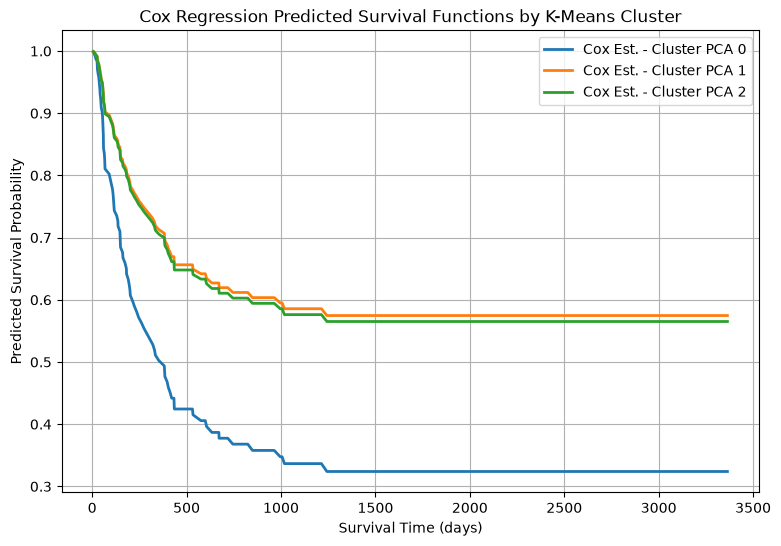

In [32]:
df_cox_clustered = df_cox.copy()
df_cox_clustered['cluster_pca'] = clusters_pca

plt.figure(figsize=(9, 6))

for cluster_id in sorted(df_cox_clustered['cluster_pca'].unique()):
  cluster_mean_profile = df_cox_clustered[
      df_cox_clustered['cluster_pca'] == cluster_id
  ].drop(columns=['survival_time', 'survival_status', 'cluster_pca']).mean()

  surv_func = cph.predict_survival_function(cluster_mean_profile)

  plt.plot(
      surv_func.index,
      surv_func.values,
      label=f'Cox Est. - Cluster PCA {cluster_id}',
      linewidth=2,
  )

plt.title('Cox Regression Predicted Survival Functions by K-Means Cluster')
plt.xlabel('Survival Time (days)')
plt.ylabel('Predicted Survival Probability')
plt.legend()
plt.grid(True)
plt.show()

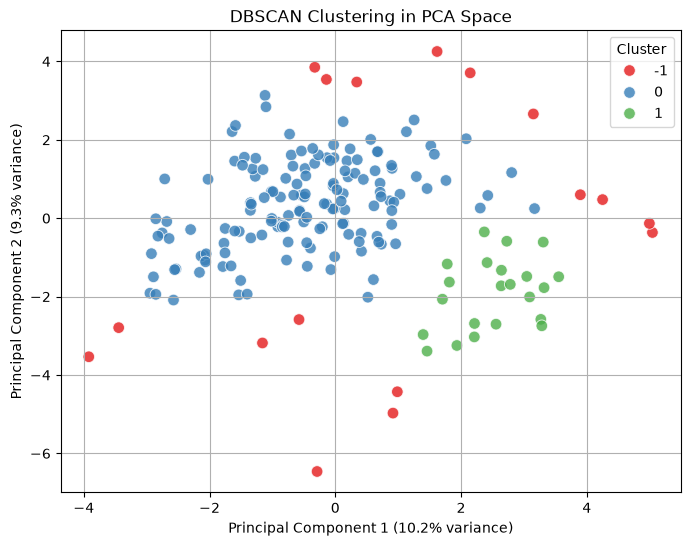

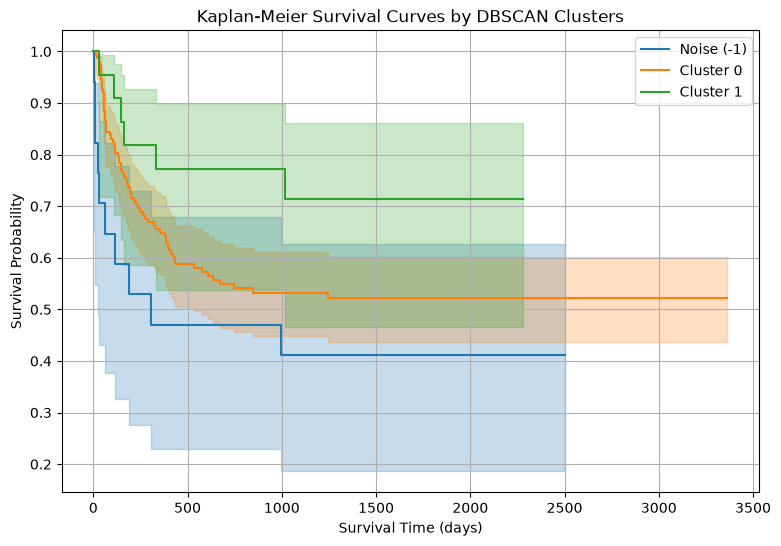

Log-Rank Test p-value: 0.07887


In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Scaling & PCA
X_final_numeric = pd.get_dummies(X_final, drop_first=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final_numeric)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. DBSCAN Clustering
dbscan = DBSCAN(eps=0.85, min_samples=5)
clusters_dbscan = dbscan.fit_predict(X_pca)

X_final_clustered_db = X_final.copy()
X_final_clustered_db['cluster_dbscan'] = clusters_dbscan

# 3. PCA Scatter Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_dbscan,
    palette='Set1',
    s=70,
    alpha=0.8,
)
plt.title('DBSCAN Clustering in PCA Space')
plt.xlabel(
    f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%'
    ' variance)'
)
plt.ylabel(
    f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%'
    ' variance)'
)
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# 4. Kaplan-Meier Survival Plot
df_survival_db = X_final_clustered_db.copy()
df_survival_db['survival_time'] = X['survival_time']
df_survival_db['survival_status'] = Y['survival_status']

kmf = KaplanMeierFitter()
plt.figure(figsize=(9, 6))

for cluster_id in sorted(df_survival_db['cluster_dbscan'].unique()):
  mask = df_survival_db['cluster_dbscan'] == cluster_id
  label_name = (
      'Noise (-1)' if cluster_id == -1 else f'Cluster {cluster_id}'
  )  #[cite: 1]
  kmf.fit(
      durations=df_survival_db.loc[mask, 'survival_time'],
      event_observed=df_survival_db.loc[mask, 'survival_status'],
      label=label_name,
  )
  kmf.plot_survival_function(ci_show=True)

plt.title('Kaplan-Meier Survival Curves by DBSCAN Clusters')
plt.xlabel('Survival Time (days)')
plt.ylabel('Survival Probability')
plt.grid(True)
plt.show()

# 5. Log-Rank Test
res_db_logrank = multivariate_logrank_test(
    event_durations=df_survival_db['survival_time'],
    groups=df_survival_db['cluster_dbscan'],
    event_observed=df_survival_db['survival_status'],
)

print(f'Log-Rank Test p-value: {res_db_logrank.p_value:.5f}')

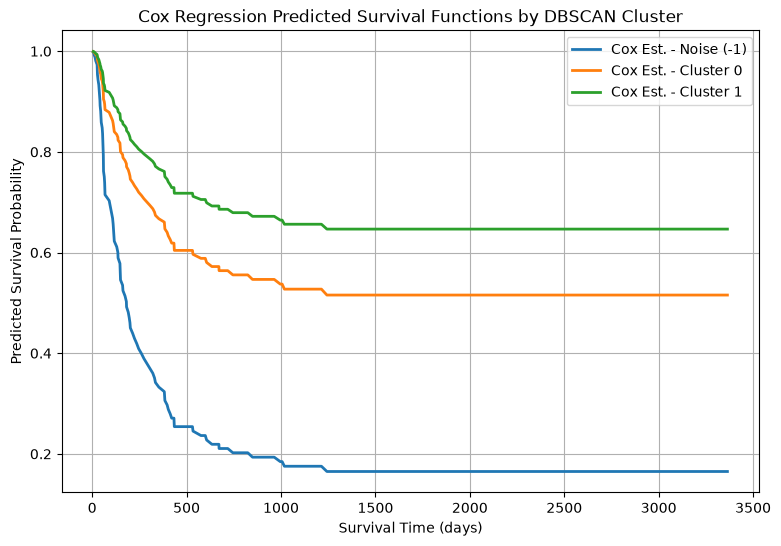

In [37]:
df_cox_db_clustered = df_cox_db.copy()
df_cox_db_clustered['cluster_dbscan'] = clusters_dbscan

plt.figure(figsize=(9, 6))

for cluster_id in sorted(df_cox_db_clustered['cluster_dbscan'].unique()):
  cluster_mask = df_cox_db_clustered['cluster_dbscan'] == cluster_id
  cluster_mean_profile = df_cox_db_clustered[cluster_mask].drop(
      columns=['survival_time', 'survival_status', 'cluster_dbscan']
  ).mean()

  surv_func = cph_db.predict_survival_function(cluster_mean_profile)
  label_name = (
      'Cox Est. - Noise (-1)'
      if cluster_id == -1
      else f'Cox Est. - Cluster {cluster_id}'
  )

  plt.plot(
      surv_func.index,
      surv_func.values,
      label=label_name,
      linewidth=2,
  )

plt.title('Cox Regression Predicted Survival Functions by DBSCAN Cluster')
plt.xlabel('Survival Time (days)')
plt.ylabel('Predicted Survival Probability')
plt.legend()
plt.grid(True)
plt.show()